# Supplementary Figure S4 — plotting


In [3]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT=Path(os.environ.get("MITOXY_PROJECT_ROOT","/scratch/ar58064/mitoxy")).resolve()
BLUE="#087EBD"; ORANGE="#E36A00"; TEAL="#00A67E"; PURPLE="#8053A6"
DARK="#202832"; MID="#667386"; GRID="#DDE3E9"; BAND="#F2F5F8"
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":10,"axes.labelcolor":DARK,
 "xtick.color":MID,"ytick.color":DARK,"axes.edgecolor":"#AEB8C4","axes.spines.top":False,
 "axes.spines.right":False,"figure.facecolor":"white","axes.facecolor":"white","savefig.facecolor":"white"})

def panel_letter(ax,letter):
    ax.text(-.14,1.08,letter,transform=ax.transAxes,fontsize=21,fontweight="bold",color=DARK,va="top")

def band_rows(ax,n):
    for i in range(n):
        if i%2==0: ax.axhspan(i-.5,i+.5,color=BAND,zorder=0)

def p_text(p): return "P < 1e-4" if p < 1e-4 else f"P = {p:.3f}"

def stat_box(ax,y,text,color,x=.76):
    # Keep x in axes space while anchoring y to the plotted data rows.
    ax.text(x,y,text,transform=ax.get_yaxis_transform(),ha="left",va="center",fontsize=8.0,fontweight="bold",color=color,
            bbox=dict(boxstyle="round,pad=.26",facecolor="white",edgecolor=color,alpha=.95,linewidth=1))

def reserve_stat_space(ax,fraction=.48):
    # Create a dedicated right-side lane beyond all confidence intervals.
    left,right=ax.get_xlim(); span=right-left
    ax.set_xlim(left,right+span*fraction)

def save_all(fig,stem,folder):
    folder.mkdir(parents=True,exist_ok=True)
    for ext in ["png","pdf","svg"]:
        fig.savefig(folder/f"{stem}.{ext}",dpi=320 if ext=="png" else None,bbox_inches="tight")

DATA_DIR=PROJECT_ROOT/"data"/"processed"/"supplementary_figure_s4"; FIGURE_DIR=PROJECT_ROOT/"figures"/"supplementary_figure_s4"
a=pd.read_csv(DATA_DIR/"panel_a_gene_regional_variation.csv"); b=pd.read_csv(DATA_DIR/"panel_b_evolution_omnibus.csv")


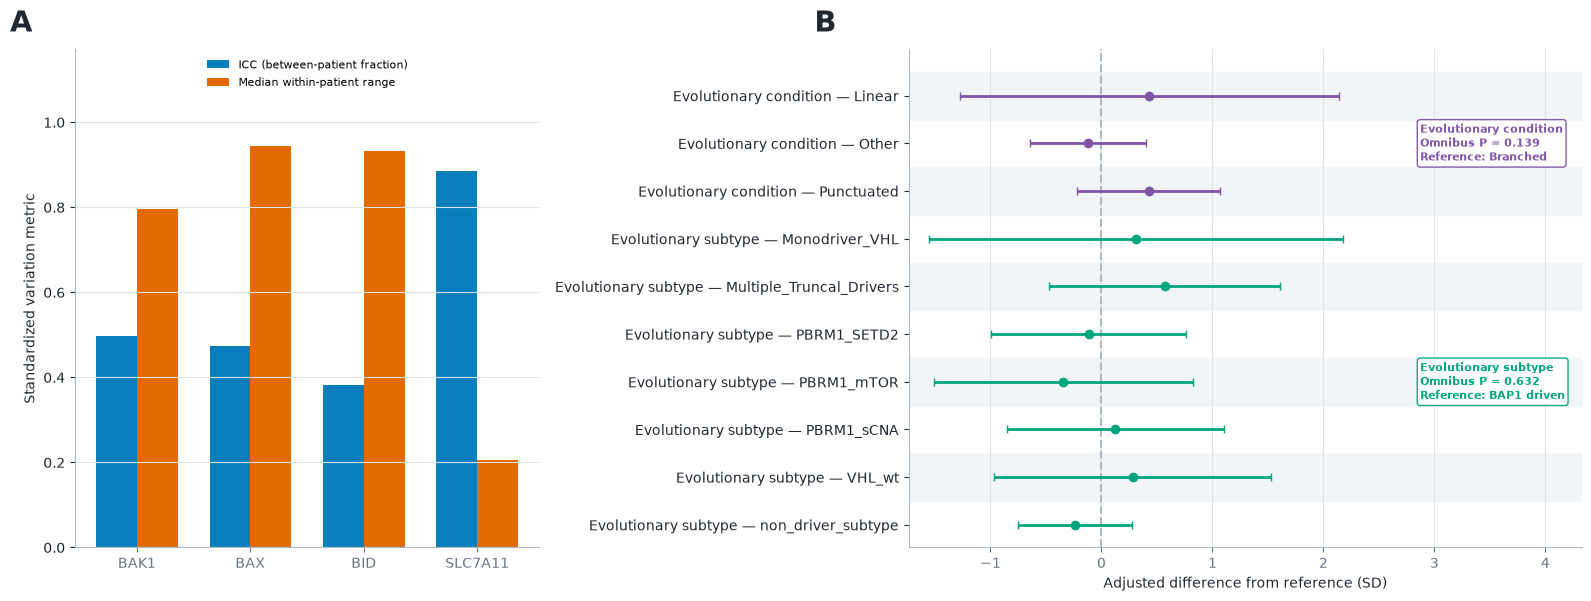

In [5]:
fig,axes=plt.subplots(1,2,figsize=(15.8,5.9),gridspec_kw={"width_ratios":[1,1.45]},constrained_layout=True)
ax=axes[0]; x=np.arange(len(a)); width=.36
ax.bar(x-width/2,a.icc,width,color=BLUE,label="ICC (between-patient fraction)")
ax.bar(x+width/2,a.median_within_range,width,color=ORANGE,label="Median within-patient range")
ax.set_xticks(x,a.gene); ax.set_ylabel("Standardized variation metric"); ax.grid(axis="y",color=GRID)
ax.set_ylim(0,max(a.icc.max(),a.median_within_range.max())*1.24)
ax.legend(frameon=False,fontsize=8.2,loc="upper center",ncol=1,borderaxespad=.5)
ax.set_title("",loc="left",fontweight="bold"); panel_letter(ax,"A")

ax=axes[1]; labels=b.classification+" — "+b.level; y=np.arange(len(b)); band_rows(ax,len(b)); ax.axvline(0,color="#AEB8C4",ls="--")
for i,row in b.reset_index(drop=True).iterrows():
    color=PURPLE if row.classification=="Evolutionary condition" else TEAL
    ax.errorbar(row.effect,i,xerr=[[row.effect-row.ci_low],[row.ci_high-row.effect]],fmt="o",color=color,capsize=3,lw=2)
reserve_stat_space(ax)
groups=list(b.reset_index(drop=True).groupby("classification",sort=False))
for j,(name,group) in enumerate(groups):
    p=group.omnibus_p.iloc[0]; reference=str(group.reference.iloc[0]).replace("_"," ")
    group_y=float(group.index.to_numpy().mean())
    stat_box(ax,group_y,f"{name}\nOmnibus {p_text(p)}\nReference: {reference}",PURPLE if j==0 else TEAL)
ax.set_yticks(y,labels); ax.invert_yaxis(); ax.set_xlabel("Adjusted difference from reference (SD)"); ax.grid(axis="x",color=GRID)
ax.set_title("",loc="left",fontweight="bold"); panel_letter(ax,"B")
save_all(fig,"Supplementary_Figure_S4",FIGURE_DIR); plt.show()

